# Overview plots — Milan Multiome (EMT / aneuploidy)

This notebook produces a handful of summary figures for the experimental team to
look at. It reads the processed RNA object (`rna_processed.h5ad`) that
`scripts/processing.py` writes, and saves every figure into
`results/figures/`.

**What you'll see below**
1. **Aneuploidy per sample** — how much of each cell's genome differs from the
   normal (DMSO) karyotype, averaged per sample. Higher = more aneuploid.
2. **EMT score per sample** — how far each sample has moved along the
   epithelial→mesenchymal transition.
3. **UMAPs** — a 2-D "map" of all cells, coloured by sample, by EMT score, and
   by aneuploidy.
4. **Aneuploidy vs EMT** — do more-aneuploid cells also show more EMT?
5. **ATAC-vs-RNA cross-check** — confirms the highly-aneuploid cells are real
   (high in both modalities), not an artefact of one method.

You don't need to change anything except the paths in the next cell.

In [1]:
import sys, os
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# reuse the exact cross-check figure from the processing script
sys.path.append(os.path.abspath(".."))
from processing import plot_crosscheck

PROJECT  = "/store24/project24/ladcol_023/Milan_Multiome"
RNA_H5AD = os.path.join(PROJECT, "data", "rna_processed.h5ad")
FIG_DIR  = os.path.join(PROJECT, "scripts/repo_EMT_aneuploidy/results", "figures")
os.makedirs(FIG_DIR, exist_ok=True)
sc.settings.figdir = FIG_DIR

SAMPLE_ORDER   = ["DMSO_D0", "REV_D0", "DMSO_D3", "REV_D3", "DMSO_D7", "REV_D7"]
REV_TIMEPOINTS = ["REV_D0", "REV_D3", "REV_D7"]
EMT_SCORE      = "EMT_up_score"
# blue = DMSO (control), red = REV (reversine / transient aneuploidy)
COLORS = ["#4C72B0" if s.startswith("DMSO") else "#C44E52" for s in SAMPLE_ORDER]

rna = ad.read_h5ad(RNA_H5AD)
rna.obs["sample"] = rna.obs["sample"].astype("category")
print(rna)

/store24/project24/ladcol_023/miniconda3/envs/scanalysis/lib/python3.10/site-packages/muon/_core/preproc.py:31: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  if Version(scanpy.__version__) < Version("1.10"):


AnnData object with n_obs × n_vars = 23506 × 46804
    obs: 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'n_genes', 'n_counts', 'sample', 'condition', 'day', 'epi_score', 'mesen_score', 'EMT_score', 'epithelial_score', 'mesenchymal_score', 'luminal_score', 'basal_score', 'pEMT_score', 'EMT_down_score', 'EMT_partial_score', 'EMT_up_score', 'cnv_burden', 'cnv_burden_proportion', 'copykat_dev'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'cnv_baseline', 'cnv_bins', 'hvg', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_umap', 'cnv'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'


## 1. Aneuploidy burden per sample

Each bar is the average fraction of the genome that differs from the normal
(DMSO) karyotype, with the error bar showing cell-to-cell spread (± standard
deviation). If reversine induced lasting aneuploidy you'd expect the red (REV)
bars to sit above the blue (DMSO) bars, and to fall from day 0 to day 7 as
unstable cells are lost.

/tmp/ipykernel_58122/444638010.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = rna.obs.groupby("sample")["cnv_burden_proportion"]


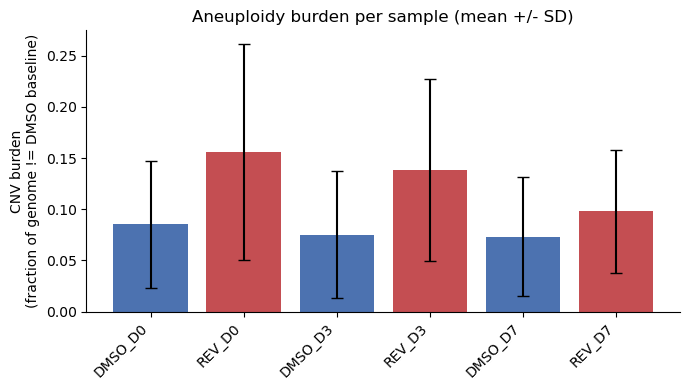

In [9]:
g = rna.obs.groupby("sample")["cnv_burden_proportion"]
mean = g.mean().reindex(SAMPLE_ORDER)
std  = g.std().reindex(SAMPLE_ORDER)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(SAMPLE_ORDER, mean.values, yerr=std.values, color=COLORS, capsize=4)
ax.set_ylabel("CNV burden\n(fraction of genome != DMSO baseline)")
ax.set_title("Aneuploidy burden per sample (mean +/- SD)")
plt.xticks(rotation=45, ha="right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "cnv_burden_barplot.png"), dpi=150)
plt.show()

## 2. EMT score per sample

Distribution of the EMT-up score in every sample. Higher = more mesenchymal
(more transitioned). The box shows the middle 50% of cells; the line is the
median.

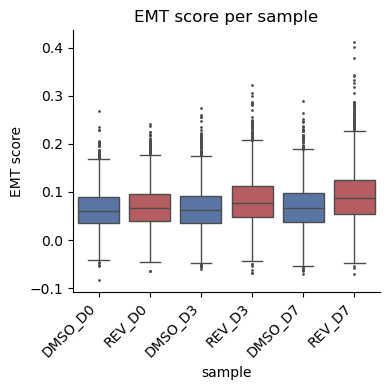

In [11]:
fig, ax = plt.subplots(figsize=(4, 4))
sns.boxplot(data=rna.obs, x="sample", y=EMT_SCORE, hue="sample", order=SAMPLE_ORDER,
            palette=COLORS, ax=ax, fliersize=1)
ax.set_title("EMT score per sample")
ax.set_ylabel("EMT score")
plt.xticks(rotation=45, ha="right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "emt_boxplot.png"), dpi=150)
plt.show()

## 3. UMAPs

A UMAP places each cell on a 2-D map so that similar cells sit close together.
The same map is coloured three ways: by sample, by EMT score, and by aneuploidy
burden. Comparing them shows whether EMT state and aneuploidy track particular
regions of the map (i.e. particular cell states).

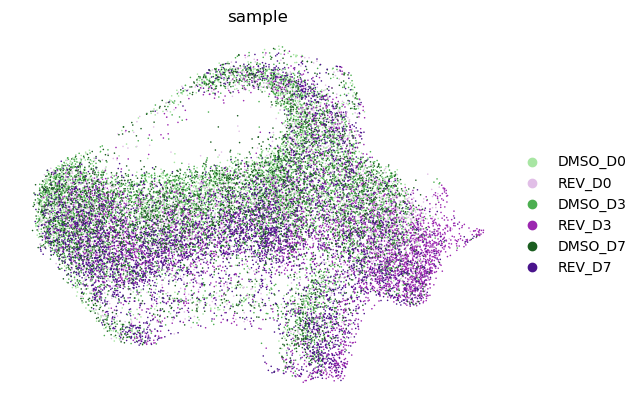

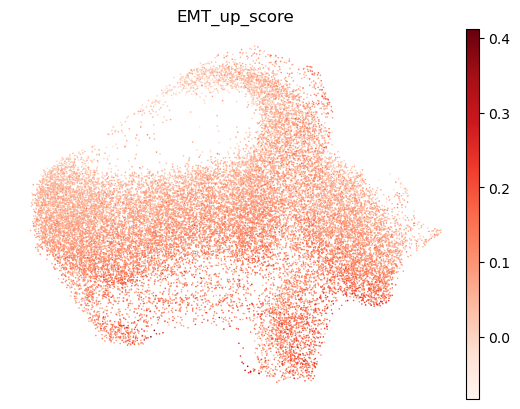

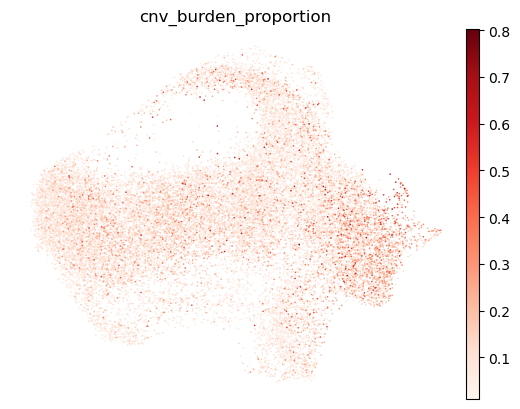

In [15]:
for color in ["sample", EMT_SCORE, "cnv_burden_proportion"]:
    sc.pl.umap(rna, color=color, cmap="Reds",
               frameon=False,
               save=f"_{color}.png", show=True)

## 4. Aneuploidy vs EMT

Each dot is a reversine (REV) cell: aneuploidy burden on the x-axis, EMT score on
the y-axis, coloured by timepoint. The Spearman correlation (rho) and its
p-value quantify whether more-aneuploid cells tend to be more mesenchymal. A
per-timepoint breakdown is printed below the plot.

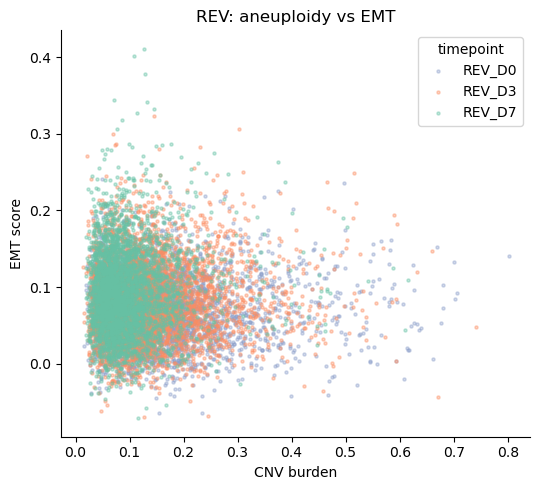

Per-timepoint Spearman correlation (REV):
  REV_D0: rho=-0.005  p=7.52e-01  n=3807
  REV_D3: rho=0.039  p=1.01e-02  n=4308
  REV_D7: rho=0.020  p=2.19e-01  n=3610


In [18]:
rev = rna.obs[rna.obs["condition"] == "REV"]

fig, ax = plt.subplots(figsize=(5.5, 5))
for tp, c in zip(REV_TIMEPOINTS, ["#8DA0CB", "#FC8D62", "#66C2A5"]):
    d = rev[rev["sample"] == tp]
    ax.scatter(d["cnv_burden_proportion"], d[EMT_SCORE],
               s=5, alpha=0.4, label=tp, color=c)
ax.set_xlabel("CNV burden")
ax.set_ylabel("EMT score")
ax.set_title(f"REV: aneuploidy vs EMT")
ax.legend(title="timepoint")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "burden_vs_emt_scatter.png"), dpi=150)
plt.show()

print("Per-timepoint Spearman correlation (REV):")
for tp in REV_TIMEPOINTS:
    d = rev[rev["sample"] == tp]
    r, pp = spearmanr(d["cnv_burden_proportion"], d[EMT_SCORE])
    print(f"  {tp}: rho={r:.3f}  p={pp:.2e}  n={len(d)}")

## 5. ATAC-vs-RNA aneuploidy cross-check

For each REV timepoint: epiAneufinder+ aneuploidy from the ATAC side (x-axis)
versus copyKat deviation from the RNA side (y-axis). Genuinely aneuploid cells
score high on **both** and lie on the diagonal; cells that are high on ATAC but
normal on RNA (bottom-right) are suspected CNV-inference failures. A positive
correlation with a clean diagonal is the reassurance that the high-aneuploidy
population is real.

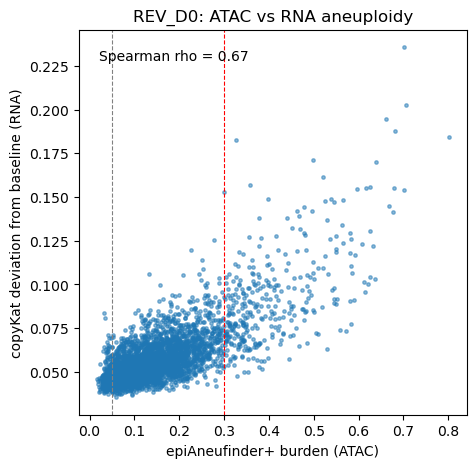

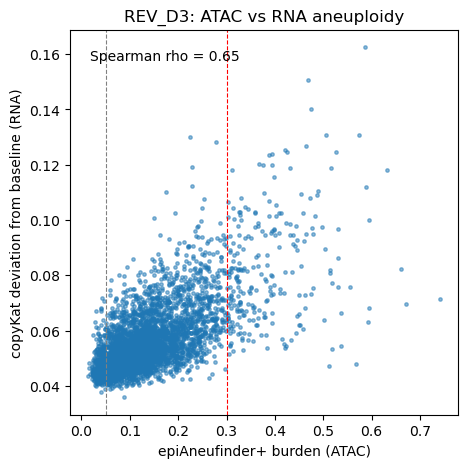

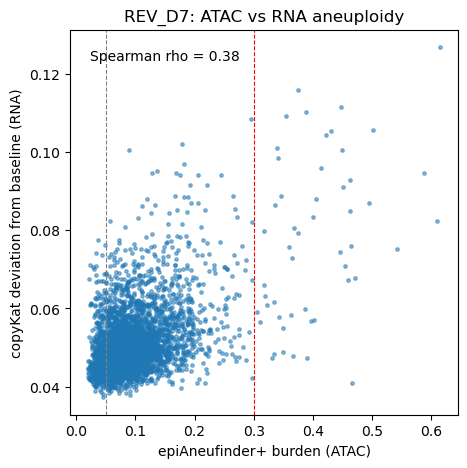

In [19]:
for tp in REV_TIMEPOINTS:
    fig = plot_crosscheck(rna, tp)
    fig.savefig(os.path.join(FIG_DIR, f"crosscheck_{tp}.png"), dpi=150)
    plt.show()